# Connectivity

Contents:
- Common operations on a network (using the routable graph built in 8.2)
- Connected components: is the network one connected piece?
- Node degree (cardinality): how many connections each node has
- Centrality: which nodes and edges are most important
  - Degree centrality
  - Betweenness centrality
  - Closeness centrality
- Checking and cleaning network topology
- Other uses of networks (brief) — morphology, spatial weights, etc.

In the previous section, we used a street network to find the shortest routes between locations. However, routing is only one of the many things that we can do with networks. Networks can also tell us a lot about the structure of the area that they represent, and checking this structure is a good idea before using a network for any analysis. For example, is it possible to travel between all parts of the network? How many streets meet at each intersection? Which streets and intersections are the most important ones for moving around in the city? In this and the next two sections, we go through common network operations that help us answer these kinds of questions. In this section, we focus on the first question, which concerns the **connectivity** of the network. We use the `networkx`[^networkx] and `osmnx`[^osmnx] libraries and a drivable street network of the Helsinki city centre, similar to the one that we used in the previous section. At the end of the section, we apply the same ideas to a river network and a power grid.

Let's start by retrieving the street network from OpenStreetMap in the same way as in the previous section. This time, we use a slightly larger area that extends 3500 meters from the center point in each direction:

In [1]:
import networkx as nx
import osmnx as ox
import pandas as pd

center_point = (60.162, 24.937)
G = ox.graph_from_point(center_point, dist=3500, network_type="drive", simplify=False)

Now we have the street network stored in the variable `G` as a `MultiDiGraph`, just like in the previous section. Next, we will check whether it is possible to travel between all parts of this network.

## Connected components

One of the first things to check about a network is whether it is **connected**, i.e. whether it is possible to travel from any node of the network to any other node along the edges. A network that is not connected consists of several separate parts that are called **connected components** (a connected network has only one component). Within a connected component, every node can be reached from every other node, but it is not possible to travel from one component to another. For instance, an island without any road connection to the mainland forms its own connected component in a street network, like the island in the south-east corner of the street network data that we used in Chapter 8.1.

With directed graphs, such as our street network, connectivity can be defined in two ways. A directed graph is **weakly connected** if all of its nodes can be reached from each other when we ignore the directions of the edges, i.e. when we pretend that all streets could be traveled in both directions. A directed graph is **strongly connected** if all of its nodes can be reached from each other also when we follow the directions of the edges. For instance, a street network that has a one-way street leading to a dead end would be weakly connected, but not strongly connected, because there would be no way to drive out of the dead end. Correspondingly, a directed graph can be divided into weakly connected components and strongly connected components. Let's see how many of both our street network has:

In [2]:
print("Weakly connected components:", nx.number_weakly_connected_components(G))
print("Strongly connected components:", nx.number_strongly_connected_components(G))

Weakly connected components: 1
Strongly connected components: 324


As we can see, the network consists of only one weakly connected component. This is because `osmnx` keeps by default only the largest weakly connected component of the network when it retrieves the data (you can change this with the `retain_all` parameter). However, the network consists of several strongly connected components, which means that it is not possible to drive in both directions between all nodes of the network. A common reason for this is that we retrieved the data only for a limited area, which means that the streets are cut at the border of the area. If a one-way street leads out of the area, we can drive into the street from the rest of the network, but once we are on it, there is no way back, because the rest of the street is outside of our area (or the other way around, if the street leads into the area). Hence, each node along such a street forms a strongly connected component of its own.

Let's find the largest strongly connected component of the network and see how many nodes it contains. The `nx.strongly_connected_components()` function returns each component as a set (i.e. a collection of unique values) of node ids. We can find the largest component, i.e. the one with the most nodes, by using the built-in `max()` function of Python with the `key=len` argument, which compares the components based on their length, i.e. the number of nodes in them:

In [3]:
largest_component = max(nx.strongly_connected_components(G), key=len)

print("Nodes in the whole network:", G.number_of_nodes())
print("Nodes in the largest strongly connected component:", len(largest_component))

Nodes in the whole network: 17792
Nodes in the largest strongly connected component: 17348


As we can see, most of the nodes belong to the largest strongly connected component. To see where the other nodes are located, let's select the nodes that do not belong to the largest component and plot them in red on top of the street network. Here, we first extract the nodes and edges of the graph as `GeoDataFrames` like in the previous section. The index of the `nodes` GeoDataFrame contains the node ids, and we can use the `.isin()` method to check which of them are part of the largest component (the `~` character reverses the selection):

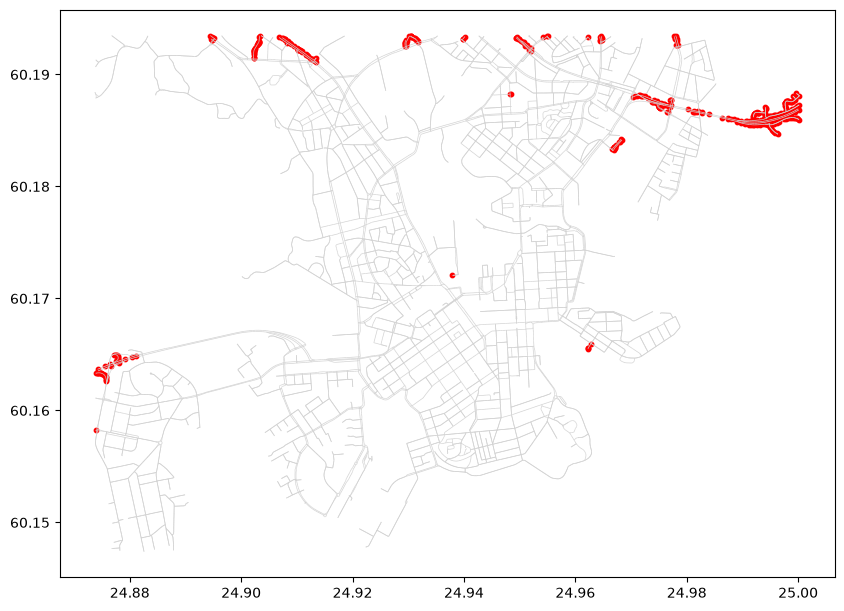

In [4]:
nodes, edges = ox.graph_to_gdfs(G)
outside_nodes = nodes.loc[~nodes.index.isin(largest_component)]

ax = edges.plot(color="lightgrey", linewidth=0.5, figsize=(10, 10))
ax = outside_nodes.plot(ax=ax, color="red", markersize=10)

_**Figure 8.X.** Nodes that do not belong to the largest strongly connected component of the street network (in red)._

The red nodes on the map show the places where it is not possible to drive both to and from the rest of the network. Typically, they are located along one-way streets near the border of the area, as discussed above, but they can also be caused, for example, by a one-way street that leads to a dead end. Let's test what happens if we try to find a route between one of these nodes and a node that belongs to the largest component. We can check whether a route exists between two nodes with the `nx.has_path()` function:

In [5]:
node_outside = outside_nodes.index[0]
node_inside = list(largest_component)[0]

print("Route from outside to inside:", nx.has_path(G, node_outside, node_inside))
print("Route from inside to outside:", nx.has_path(G, node_inside, node_outside))

Route from outside to inside: False
Route from inside to outside: True


As we can see, at least one of the two routes does not exist, i.e. we cannot drive between these two nodes in both directions. If we tried to find such a route with the `nx.dijkstra_path()` function that we used in the previous section, `networkx` would raise an error. For this reason, it is common to keep only the largest strongly connected component of the network for routing and other network analyses. With `osmnx`, we can do this with the `ox.truncate.largest_component()` function by setting the `strongly` parameter to `True`:

In [6]:
G = ox.truncate.largest_component(G, strongly=True)
print("Number of nodes:", G.number_of_nodes())

Number of nodes: 17348


As we can see, the number of nodes is now the same as the number of nodes in the largest strongly connected component above. Our graph now only keeps the nodes and edges that can be reached from every part of the network, which means that we can drive from every node to every other node.

## Reachability in directed networks

Thus far in this chapter, we have used networks to represent streets. However, networks are used for many other purposes in GIS as well. For instance, in spatial statistics, the neighbor relationships between areas, such as which neighborhoods share a border, are often represented as a graph (called spatial weights), and in urban studies, network measures, such as the number of streets that meet at each intersection, are used to compare the street patterns of different cities. In addition, many phenomena form networks themselves, and the network operations that we have learned so far can be applied to them in a similar manner as to streets. In the rest of this section, we look at two examples: a river network and an electricity grid. We retrieve both of them from OpenStreetMap with the `pyrosm` library that we introduced in the previous section, because our examples cover large areas. In OpenStreetMap, the type of each feature is described with **tags**, which are key-value pairs such as `highway=residential` for a residential street or `waterway=river` for a river[^osm_tags]. With `pyrosm`, we can retrieve any type of line features as a network by passing a custom filter to the `get_network()` method. The filter tells which tags the features should have, and it is written in a similar format as the queries of the Overpass API, e.g. `'["waterway"="river"]'` for rivers.

Rivers form natural networks in which smaller rivers (tributaries) join larger ones, and the water flows from upstream to downstream. Let's examine the rivers in Acre, a state in the western part of the Brazilian Amazon. We download the data with the `get_data_by_geocoding()` function that we used in the previous section, and select the rivers with a custom filter that keeps only the features tagged with `waterway=river`:

Finding the extracts: reading the extract sizes:  97%|#########6| 00:02<00:00

/var/folders/f2/pgp09jl542zffhtrt2hx8zhh0000gp/T/ipykernel_9833/1123888818.py:5: UserWarning: Movisda BR-AC leaves out 85 km² (0.052 %) of the area. This part lies along the edge of the area.
  fp_acre = get_data_by_geocoding("Acre, Brazil")


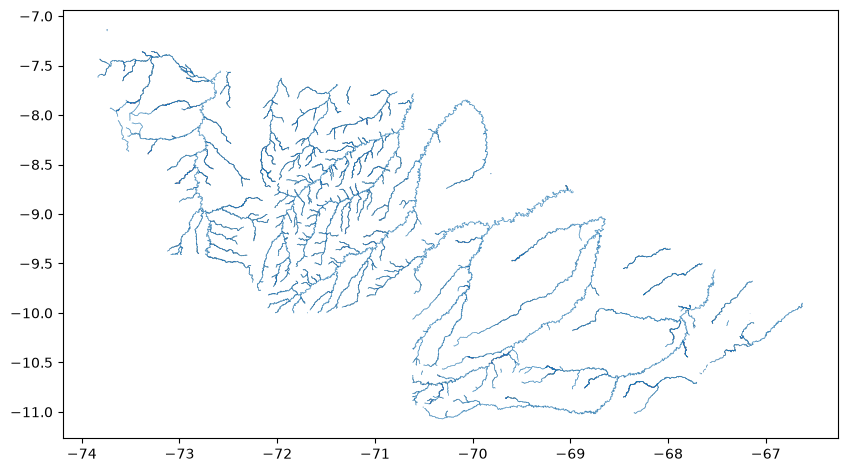

In [7]:
from pyrosm import OSM, get_data_by_geocoding
import geopandas as gpd
import shapely

fp_acre = get_data_by_geocoding("Acre, Brazil")
osm_acre = OSM(fp_acre)
river_nodes, rivers = osm_acre.get_network(
    custom_filter='["waterway"="river"]', nodes=True
)
ax = rivers.plot(linewidth=0.5, figsize=(10, 8))

_**Figure 8.X.** Rivers in the state of Acre in Brazil, based on OpenStreetMap data._

As we can see, Acre is covered by a dense network of rivers. Similarly as in the previous section, `pyrosm` also printed a warning above the figure, because the downloaded PBF file does not cover the whole boundary polygon of Acre, and hence a small part of the area is missing from our data. In this case, the missing part is less than 0.1 % of the area and consists mostly of narrow strips along the border of the state, which does not affect our analysis.

Next, let's use our river data as a network. Water flows only in one direction, and hence rivers form a directed network (as we mentioned in Chapter 8.1). In OpenStreetMap, rivers are drawn in the direction of the flow, which means that the `u` and `v` columns of our data tell from which node to which node the water flows in each segment. Hence, we can build a directed graph from the river segments with the `nx.from_pandas_edgelist()` function, which creates a graph from a table in which each row represents an edge:

In [8]:
G_river = nx.from_pandas_edgelist(
    rivers, source="u", target="v", create_using=nx.MultiDiGraph
)

In a directed network, a node is **reachable** from another node if there is a path between them that follows the directions of the edges, which is what we checked with the `nx.has_path()` function earlier in this section. In a river network, this tells us, for instance, which parts of the network are located upstream of a given location, i.e. from where the water flows to the location. This kind of information is useful, e.g. when assessing where floodwater or pollution could come from (the area from which water flows to a given location is called a watershed, which we will discuss in Chapter 12). Let's find the upstream river network of Cruzeiro do Sul, a city located on the bank of the Juruá river. We first find the node of the river network that is closest to the city. To measure the distances in meters, we reproject the data into a UTM coordinate reference system that we get with the `.estimate_utm_crs()` method. Then we use the `nx.ancestors()` function that returns all nodes from which there is a path to the given node (the `nx.descendants()` function does the opposite, i.e. it returns all nodes that can be reached from the given node):

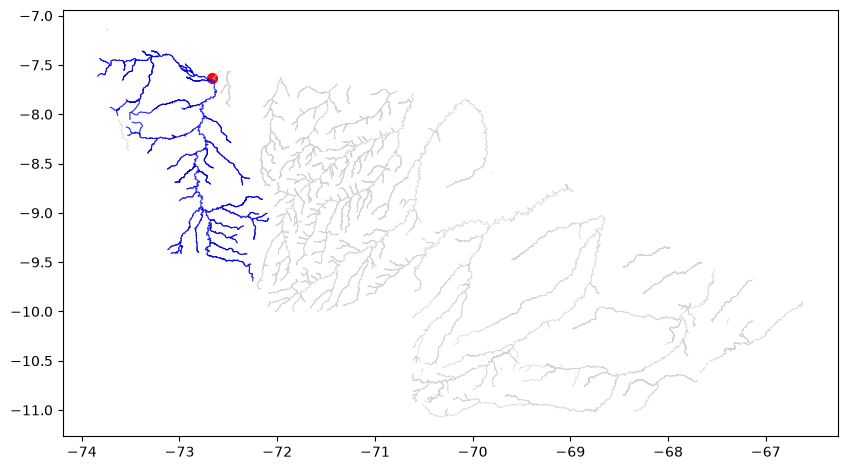

In [9]:
crs_acre = rivers.estimate_utm_crs()
city = gpd.GeoSeries([shapely.Point(-72.669, -7.636)], crs="EPSG:4326")
distances = river_nodes.to_crs(crs_acre).distance(city.to_crs(crs_acre).iloc[0])
city_node = river_nodes.loc[distances.idxmin(), "id"]

upstream_nodes = nx.ancestors(G_river, city_node)
upstream_rivers = rivers.loc[rivers["u"].isin(upstream_nodes)]

ax = rivers.plot(color="lightgrey", linewidth=0.5, figsize=(10, 8))
ax = upstream_rivers.plot(ax=ax, color="blue", linewidth=0.8)
ax = city.plot(ax=ax, color="red", markersize=50)

_**Figure 8.X.** The rivers upstream of Cruzeiro do Sul (in blue), and the location of the city (in red)._

The blue rivers in Figure 8.X show the parts of the river network from which the water flows past Cruzeiro do Sul. As we can see, they cover a large part of western Acre. Notice that the Juruá river starts in Peru, which means that the actual upstream network of the city is larger than what we can see in our data. This kind of distortion at the borders of a study area is called an *{term}`edge effect`*, and it is good to keep it in mind when interpreting the results of network analyses.

## Critical edges

Some edges are critical for keeping a network connected: if such an edge is removed, for instance because a road is closed or a power line fails, the network splits into separate parts. Let's see how we can find such edges in a power grid. Electricity is delivered from power plants to consumers through a network of power lines. The lines meet at **substations**, where the electricity is, for instance, transformed from one voltage to another and distributed to the connected lines. The power lines with the highest voltages form the transmission grid that carries electricity over long distances. A power grid is vulnerable if the failure of a single power line, e.g. due to a storm, can cut off a part of the grid from the rest of it. Hence, grid operators aim to build grids in which there is an alternative route for the electricity, if one line fails.

Let's examine the transmission grid of Iceland, which is an island with its own power grid that is not connected to other countries. We retrieve the power lines with a custom filter that keeps the features whose `power` tag contains either `line` or `cable` (the `~` character means that the value is matched as a text pattern, and the `|` character means "or"). We also keep the names and voltages of the lines. The voltages are stored in volts as text, so we convert them into numbers and keep only the lines with a voltage of at least 66 000 volts (66 kV), which belong to the transmission grid:

/var/folders/f2/pgp09jl542zffhtrt2hx8zhh0000gp/T/ipykernel_9833/1463268480.py:1: UserWarning: Movisda IS leaves out 150 km² (0.085 %) of the area. This part lies along the edge of the area.
  fp_iceland = get_data_by_geocoding("Iceland")


Cropping movisda_IS-latest.osm.pbf: writing the file: 100%|##########| 00:02<00:00

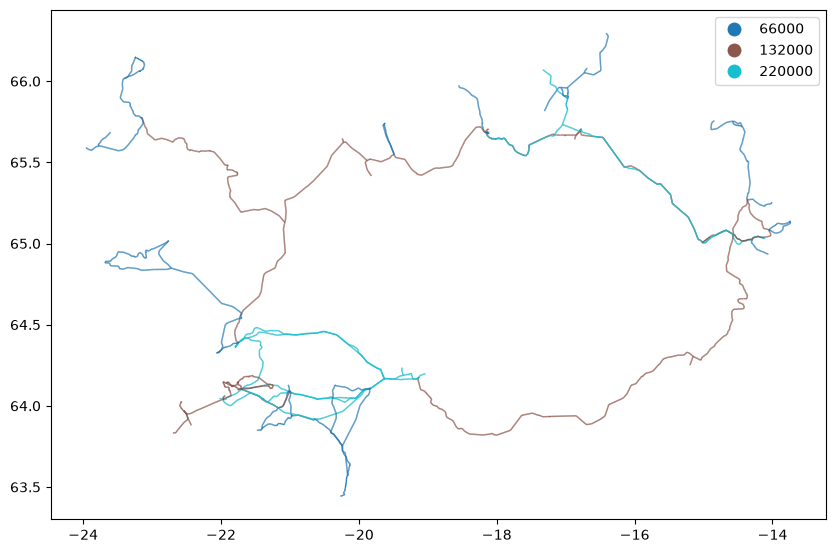

In [10]:
fp_iceland = get_data_by_geocoding("Iceland")
osm_iceland = OSM(fp_iceland)
grid_nodes, power_lines = osm_iceland.get_network(
    custom_filter='["power"~"line|cable"]',
    nodes=True,
    extra_attributes=["name", "voltage"],
)
power_lines["voltage"] = pd.to_numeric(power_lines["voltage"], errors="coerce")
power_lines = power_lines.loc[power_lines["voltage"] >= 66000]
power_lines["voltage"] = power_lines["voltage"].astype(int)

ax = power_lines.plot(
    column="voltage", categorical=True, legend=True, linewidth=1, figsize=(10, 7)
)

_**Figure 8.X.** The transmission grid of Iceland colored by the voltage of the power lines (in volts)._

### Connecting power lines at substations

Before we can analyze the grid as a network, we need to fix one topology issue in the data. In a power grid, the lines are connected to each other at substations. However, in OpenStreetMap, the substations are typically drawn as separate areas, and the lines that lead to the same substation end at different points inside or next to it. Hence, these lines do not share any node, and a graph created directly from them would consist of many separate pieces. To fix this, we read the substations with the `get_data_by_custom_criteria()` method and enlarge their areas by 50 meters with the `.buffer()` method. Then, we find the nodes of the power lines that are located within these areas with a spatial join (see Chapter 6.7). Finally, we replace the ids of these nodes in the `u` and `v` columns with the id of the substation, which connects all lines that lead to the same substation to each other. Segments that start and end at the same substation are removed:

In [11]:
substations = osm_iceland.get_data_by_custom_criteria(
    custom_filter={"power": ["substation"]}, extra_attributes=["name"]
)
crs_iceland = power_lines.estimate_utm_crs()
substation_areas = substations[["id", "name", "geometry"]].to_crs(crs_iceland)
substation_areas["geometry"] = substation_areas.buffer(50)

nodes_in_substations = gpd.sjoin(
    grid_nodes[["id", "geometry"]].to_crs(crs_iceland),
    substation_areas,
    predicate="within",
).drop_duplicates("id_left")
node_to_substation = dict(
    zip(nodes_in_substations["id_left"], nodes_in_substations["id_right"])
)

power_lines["u"] = power_lines["u"].replace(node_to_substation)
power_lines["v"] = power_lines["v"].replace(node_to_substation)
power_lines = power_lines.loc[power_lines["u"] != power_lines["v"]]

Now we can build a graph from the power lines in the same way as we did with the rivers. This time, we create an undirected graph, because electricity can flow along a power line in both directions. We also store the names of the lines as an edge attribute, and check how many connected components our grid has:

In [12]:
G_grid = nx.from_pandas_edgelist(
    power_lines, source="u", target="v", edge_attr="name", create_using=nx.MultiGraph
)
print("Connected components:", nx.number_connected_components(G_grid))

Connected components: 4


As we can see, our grid still consists of a few separate pieces. These are short pieces of power lines that are not connected to any substation in the data, for instance because a part of the line is missing in OpenStreetMap. Similarly as with the street network earlier in this section, we keep only the largest connected component for the analysis:

In [13]:
G_grid = G_grid.subgraph(max(nx.connected_components(G_grid), key=len)).copy()

### Finding bridges

Now we can find out which power lines are critical for the grid. An edge whose removal splits a network into two separate parts is called a **bridge**. In a power grid, the bridges are lines without any backup: if such a line fails, all substations behind it lose their connection to the rest of the grid. We can find the bridges with the `nx.bridges()` function, which returns the bridges as pairs of nodes. Let's mark the segments of the power lines that are bridges and plot them in red on top of the grid:

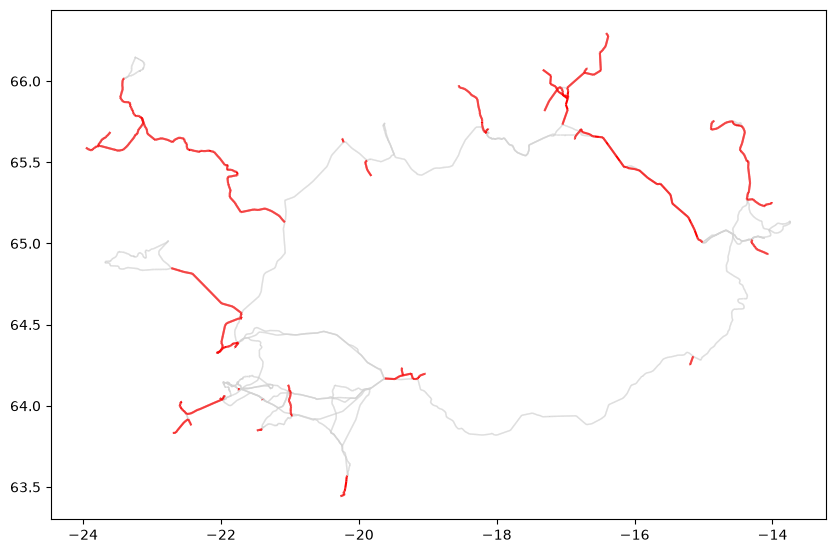

In [14]:
bridges = set(nx.bridges(G_grid))
power_lines["bridge"] = [
    (u, v) in bridges or (v, u) in bridges
    for u, v in zip(power_lines["u"], power_lines["v"])
]

ax = power_lines.plot(color="lightgrey", linewidth=1, figsize=(10, 7))
ax = power_lines.loc[power_lines["bridge"]].plot(ax=ax, color="red", linewidth=1.5)

_**Figure 8.X.** The power lines of the transmission grid of Iceland that are bridges (in red), i.e. lines whose failure would cut off a part of the grid._

As we can see, a large part of the grid forms loops, in which the electricity can take an alternative route if one line fails. However, several parts of the grid are connected to the rest of it through a single line.

### Simulating a line failure

Let's test what would happen if one of these lines, Glerárskógalína 1, failed. This line connects the Westfjords region in the northwest of Iceland to the rest of the grid. We remove all edges of the line from a copy of our graph, find the largest connected component that remains, and list the substations that are no longer part of it:

In [15]:
G_failure = G_grid.copy()
failed_line = [
    (u, v, key)
    for u, v, key, name in G_grid.edges(keys=True, data="name")
    if name == "Glerárskógalína 1"
]
G_failure.remove_edges_from(failed_line)
main_grid = max(nx.connected_components(G_failure), key=len)

grid_substations = substation_areas.loc[substation_areas["id"].isin(G_grid.nodes)]
cut_off = grid_substations.loc[~grid_substations["id"].isin(main_grid)]
cut_off["name"].dropna().tolist()

['Geiradalur',
 'Glerárskógar',
 'Breiðidalur',
 'Mjólká',
 'Keldeyri',
 'Ísafjörður',
 'Bolungarvík']

As we can see, the failure of this single line would cut off several substations from the main grid, including the substation of Ísafjörður, the largest town in the Westfjords. In practice, local power plants in the region could still produce part of the electricity, but the region would lose its connection to the rest of the grid. This kind of analysis is a simple way to find the weak points of a network, and the same approach can be applied to other networks as well, such as street networks or water pipes. Notice, however, that the results depend on how completely and accurately the grid has been mapped in OpenStreetMap, and hence they do not necessarily match the official data of the grid operator.

In this section, we learned how to check whether a network is connected, how to find the nodes that can be reached from a given node in a directed network, and how to find the edges whose failure would split a network into separate parts. In the next section, we will look at how many edges are connected to each node of a network, and how to check and fix errors in the topology of street data.

## Footnotes

[^networkx]: <https://networkx.org/documentation/stable/>
[^osmnx]: <https://osmnx.readthedocs.io/en/stable/>
[^osm_tags]: <https://wiki.openstreetmap.org/wiki/Tags>